# Card 02 – Pricing & discounts
**Question:** do discounts sell more pieces, or do they just give away margin?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

In [2]:
li = full_years(files['lines'])
print(f'lines with a discount: {li.has_discount.mean():.0%} | total discount: {M(li.discount_line_EGP.sum())} EGP')
d = li.groupby('has_discount').agg(lines=('quantity', 'size'), avg_pieces=('quantity', 'mean'), net=('net_line_EGP', 'sum'), gp=('margin_EGP', 'sum'))
d['margin_%'] = d.gp / d.net * 100
print('correlation discount % ↔ pieces:', round(li[['discount_pct', 'quantity']].corr().iloc[0, 1], 4))
d.round(2)

lines with a discount: 54% | total discount: 37.3M EGP
correlation discount % ↔ pieces: 0.0004


,lines,avg_pieces,net,gp,margin_%
has_discount,,,,,
False,519387,2.98,3.977712e+08,1.631812e+08,41.02
True,609204,2.99,4.289081e+08,1.537750e+08,35.85


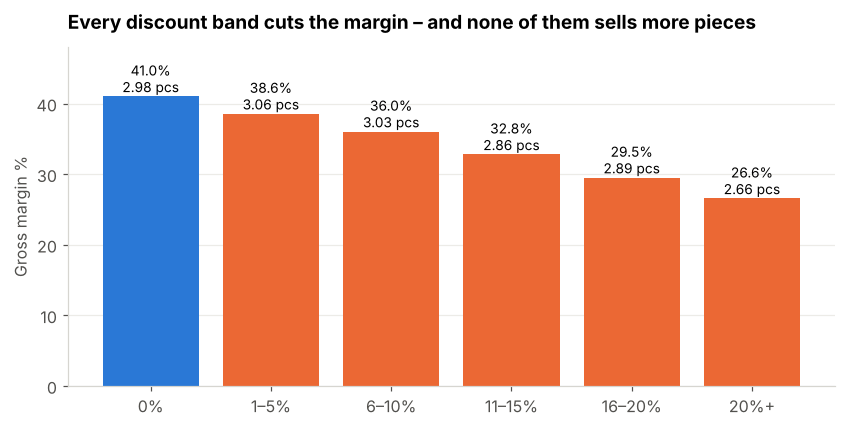

,lines,avg_pieces,net,gp,margin_%
band,,,,,
0%,519387,2.98,3.977712e+08,1.631812e+08,41.02
1–5%,235163,3.06,1.766485e+08,6.813427e+07,38.57
6–10%,186783,3.03,1.335263e+08,4.812498e+07,36.04
11–15%,123349,2.86,7.929292e+07,2.601537e+07,32.81
16–20%,54993,2.89,3.467100e+07,1.023321e+07,29.52
20%+,8916,2.66,4.769345e+06,1.267182e+06,26.57


In [3]:
li['band'] = pd.cut(li.discount_pct, [-0.001, 0, 0.05, 0.10, 0.15, 0.20, 1], labels=['0%', '1–5%', '6–10%', '11–15%', '16–20%', '20%+'])
b = li.groupby('band', observed=True).agg(lines=('quantity', 'size'), avg_pieces=('quantity', 'mean'), net=('net_line_EGP', 'sum'), gp=('margin_EGP', 'sum'))
b['margin_%'] = b.gp / b.net * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(b.index.astype(str), b['margin_%'], color=[BLUE] + [ORANGE] * (len(b) - 1))
for i, (m_, p) in enumerate(zip(b['margin_%'], b.avg_pieces)):
    ax.text(i, m_ + 0.6, f'{m_:.1f}%\n{p:.2f} pcs', ha='center', fontsize=9)
style(ax, 'Every discount band cuts the margin – and none of them sells more pieces', 'Gross margin %')
ax.set_ylim(0, 48)
save(fig, 'c02_discount_bands')
b.round(2)

by channel: {'Online': 54.2, 'Store': 53.9, 'Wholesale': 54.1}
by year   : {2019: 54.1, 2020: 54.2, 2021: 53.9, 2022: 53.9, 2023: 54.2, 2024: 54.0, 2025: 53.8, 2026: 54.0}


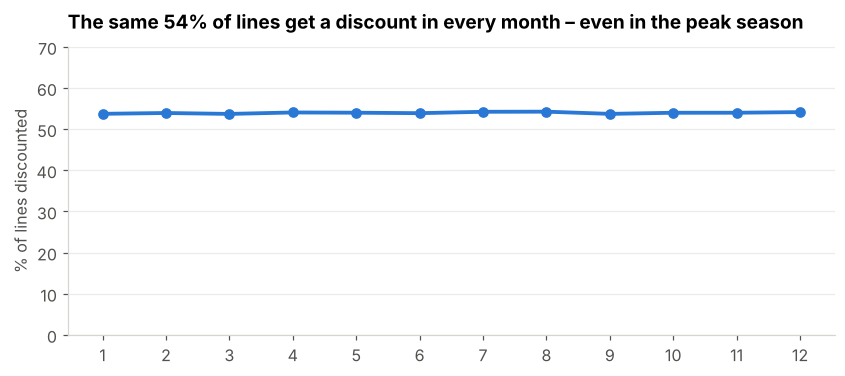

In [4]:
m_share = li.assign(m=li.order_date.dt.month).groupby('m').has_discount.mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(m_share.index, m_share, color=BLUE, lw=2.5, marker='o')
ax.set_ylim(0, 70); ax.set_xticks(range(1, 13))
style(ax, 'The same 54% of lines get a discount in every month – even in the peak season', '% of lines discounted')
save(fig, 'c02_discount_by_month')
print('by channel:', (li.groupby('channel').has_discount.mean() * 100).round(1).to_dict())
print('by year   :', (li.groupby('fy').has_discount.mean() * 100).round(1).to_dict())

In [5]:
y = li.groupby('fy').agg(discount=('discount_line_EGP', 'sum'), gp=('margin_EGP', 'sum'))
y['discount_%_of_GP'] = y.discount / y.gp * 100
print(f'FY2026: discounts {M(y.discount.iloc[-1])} EGP = {y["discount_%_of_GP"].iloc[-1]:.1f}% of gross profit')
y.assign(discount=lambda d: d.discount / 1e6, gp=lambda d: d.gp / 1e6).round(2)

FY2026: discounts 13.0M EGP = 11.7% of gross profit


,discount,gp,discount_%_of_GP
fy,,,
2019,0.87,7.35,11.78
2020,1.12,9.41,11.88
2021,1.38,11.88,11.63
2022,2.11,17.68,11.91
2023,3.39,28.41,11.93
2024,5.89,50.35,11.70
2025,9.51,80.99,11.74
2026,13.02,110.89,11.74


### What-if: replace random discounts with planned ones
Because discounts do not add pieces, money given as discount comes straight back as profit when we stop it.
We do not assume 100%: some discounts may be needed (clearance, loyalty). The share we keep is an assumption the manager can change in the dashboard.

In [6]:
d26 = y.discount.loc[2026]
pd.DataFrame({'stop % of random discounts': [25, 50, 75, 100],
              'extra gross profit / year (M EGP)': [round(d26 * p / 100 / 1e6, 2) for p in [25, 50, 75, 100]]})

,stop % of random discounts,extra gross profit / year (M EGP)
0,25,3.26
1,50,6.51
2,75,9.77
3,100,13.02


### Takeaway (card 02)
- **54%** of lines get a discount (avg 8%), the same share in every month, channel and year → it is not a strategy.
- Discounted lines sell **2.99 pieces vs 2.98** without discount (correlation 0.0004): no extra pieces.
- Margin drops from **41.0% to 35.9%**; the 20%+ band earns 26.6%.
- FY2026: **13.0M EGP** discounts = **11.7% of gross profit**. Stopping 75% of them = **+9.8M EGP/year**.
- Recommendation: discounts only as planned, measured campaigns (test vs control), with a floor margin rule.